# Fase 4 — Definición y cálculo de KPIs

Los KPIs se definen y justifican en `docs/04_kpis.md`. Aquí se calculan sobre el dataset limpio para
validar los valores que mostrará el dashboard de Power BI (las medidas DAX deben dar los mismos resultados).

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.config import FIGURES_DIR, PROCESSED_DIR, REPORTS_DIR
from src.kpis import kpi_table, kpis_by, yoy_growth

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_csv(PROCESSED_DIR / "uber_clean.csv", parse_dates=["fecha_local", "fecha"])

## 1. KPIs globales

In [2]:
kpis = kpi_table(df)
kpis.to_csv(REPORTS_DIR / "kpis_globales.csv", index=False)
kpis

,kpi,valor,unidad
0,Ingreso total,"2,166,790.70",USD
1,Total de viajes,"191,776.00",viajes
2,Tarifa promedio por viaje,11.30,USD
3,Tarifa por km,3.36,USD/km
4,Distancia promedio por viaje,3.37,km
5,% de viajes en hora pico,26.54,%
6,Ocupación promedio,1.69,pasajeros/viaje
7,% de ingresos de aeropuertos,18.40,%


## 2. KPIs por año

Nota: el último año del dataset no está completo, por lo que su ingreso total y número de viajes no son
comparables con los demás años; los KPIs de promedio sí lo son.

In [3]:
por_anio = kpis_by(df, "anio")
por_anio.to_csv(REPORTS_DIR / "kpis_por_anio.csv")
por_anio

,ingreso_total,total_viajes,tarifa_promedio,tarifa_por_km,distancia_promedio,pct_hora_pico,ocupacion_promedio,pct_ingreso_aeropuerto
2009,"293,175.91","29,493.00",9.94,3.10,3.20,27.49,1.69,15.87
2010,"291,656.45","28,927.00",10.08,3.09,3.26,27.22,1.68,16.18
2011,"311,403.07","30,120.00",10.34,3.10,3.34,26.39,1.69,17.44
2012,"343,561.96","30,777.00",11.16,3.25,3.43,26.25,1.68,18.30
2013,"380,915.16","30,144.00",12.64,3.65,3.46,26.59,1.71,19.98
2014,"373,599.61","28,948.00",12.91,3.73,3.46,25.49,1.70,20.13
2015,"172,478.54","13,367.00",12.90,3.76,3.44,26.18,1.69,21.10


In [4]:
yoy = yoy_growth(df)
yoy

,tarifa_promedio,variacion_pct
anio,,
2009,9.94,NaN
2010,10.08,1.43
2011,10.34,2.54
2012,11.16,7.97
2013,12.64,13.20
2014,12.91,2.13
2015,12.90,-0.02


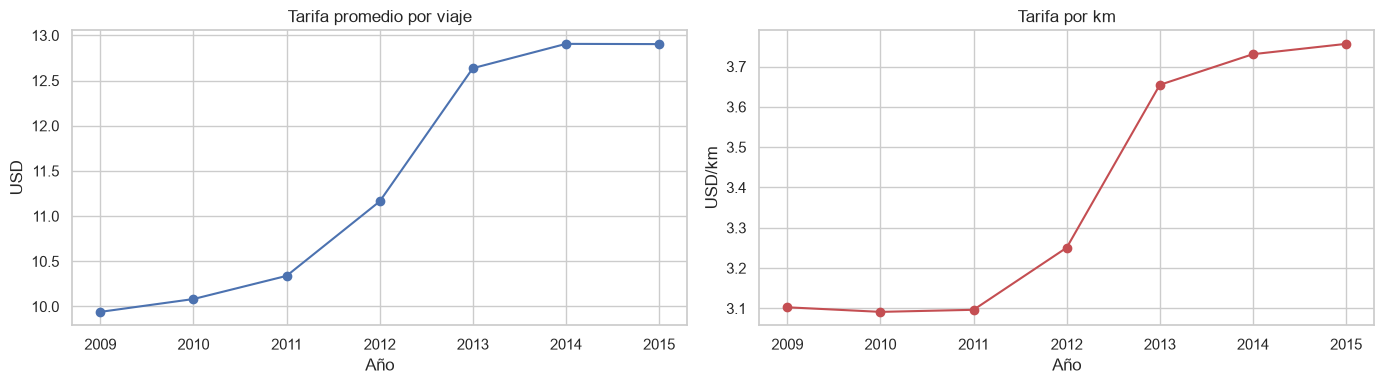

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
por_anio["tarifa_promedio"].plot(marker="o", ax=axes[0])
axes[0].set(title="Tarifa promedio por viaje", xlabel="Año", ylabel="USD")
por_anio["tarifa_por_km"].plot(marker="o", color="#C44E52", ax=axes[1])
axes[1].set(title="Tarifa por km", xlabel="Año", ylabel="USD/km")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_kpis_anio.png", dpi=120)
plt.show()

## 3. KPIs por franja horaria y tipo de día

In [6]:
orden_franjas = ["Madrugada", "Mañana", "Tarde", "Noche"]
por_franja = kpis_by(df, "franja_horaria").loc[orden_franjas]
por_franja

,ingreso_total,total_viajes,tarifa_promedio,tarifa_por_km,distancia_promedio,pct_hora_pico,ocupacion_promedio,pct_ingreso_aeropuerto
Madrugada,"296,180.85","24,641.00",12.02,2.95,4.07,0.00,1.75,11.20
Mañana,"512,247.15","46,234.00",11.08,3.48,3.18,45.50,1.60,20.99
Tarde,"637,217.22","54,969.00",11.59,3.58,3.23,22.31,1.69,24.79
Noche,"721,145.48","65,932.00",10.94,3.27,3.34,26.70,1.73,13.86


In [7]:
kpis_by(df, "es_fin_de_semana").rename(index={False: "Entre semana", True: "Fin de semana"})

,ingreso_total,total_viajes,tarifa_promedio,tarifa_por_km,distancia_promedio,pct_hora_pico,ocupacion_promedio,pct_ingreso_aeropuerto
Entre semana,"1,553,049.52","137,362.00",11.31,3.41,3.31,37.06,1.66,19.17
Fin de semana,"613,741.18","54,414.00",11.28,3.23,3.49,0.00,1.78,16.43


## 4. KPIs por tipo de trayecto

In [8]:
kpis_by(df, "aeropuerto")

,ingreso_total,total_viajes,tarifa_promedio,tarifa_por_km,distancia_promedio,pct_hora_pico,ocupacion_promedio,pct_ingreso_aeropuerto
EWR,"18,719.86",263.00,71.18,4.04,17.60,17.49,1.63,100.00
JFK,"184,087.06","3,959.00",46.50,2.53,18.36,24.80,1.75,100.00
LGA,"195,799.99","6,357.00",30.80,3.17,9.71,28.19,1.71,100.00
Ninguno,"1,768,183.79","181,197.00",9.76,3.49,2.79,26.54,1.69,0.00


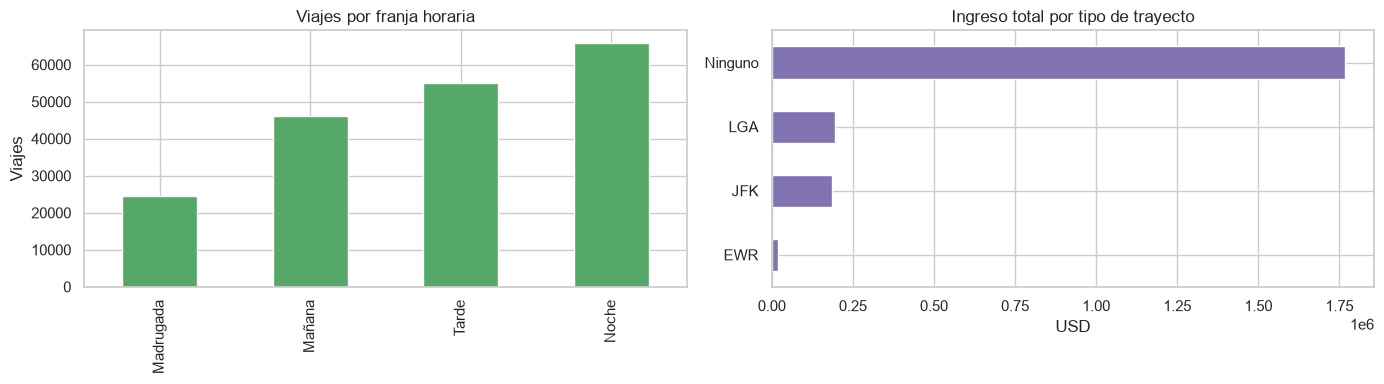

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
por_franja["total_viajes"].plot(kind="bar", ax=axes[0], color="#55A868")
axes[0].set(title="Viajes por franja horaria", xlabel="", ylabel="Viajes")
ingreso_aeropuerto = df.groupby("aeropuerto")["fare_amount"].sum().sort_values()
ingreso_aeropuerto.plot(kind="barh", ax=axes[1], color="#8172B2")
axes[1].set(title="Ingreso total por tipo de trayecto", xlabel="USD", ylabel="")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_kpis_franja_aeropuerto.png", dpi=120)
plt.show()

## 5. Interpretación

- **Volumen:** 191.776 viajes generaron **2.166.791 USD**, con un ticket promedio de **11,30 USD** y una
  distancia promedio de **3,37 km**: predominan los trayectos cortos urbanos.
- **Rentabilidad por km:** cada km genera en promedio **3,36 USD**. Este indicador subió de 3,10 USD (2009-2011)
  a 3,76 USD (2015), y el mayor salto de la tarifa promedio ocurrió en **2013 (+13,2 %)**, el primer año completo
  después del ajuste tarifario de septiembre de 2012.
- **Demanda por franja:** la **noche** (18-23 h) concentra más viajes (65.932) e ingresos (721.145 USD); la
  **tarde** tiene la tarifa por km más alta (3,58 USD). La madrugada tiene el ticket más alto (12,02 USD)
  porque sus viajes son más largos (4,07 km).
- **Hora pico:** el **26,5 %** de los viajes ocurre en hora pico; en la franja de la mañana llega al 45,5 %.
- **Tipo de día:** entre semana y fin de semana el ticket es casi igual (11,31 vs. 11,28 USD), lo que confirma H3.
- **Ocupación:** **1,69 pasajeros por viaje**; el 69 % de los viajes lleva un solo pasajero.
- **Aeropuertos:** solo el **5,5 %** de los viajes (10.579) aporta el **18,4 %** de los ingresos. El ticket es
  de 71,18 USD en EWR, 46,50 USD en JFK y 30,80 USD en LGA, frente a 9,76 USD del resto. Su participación en
  los ingresos crece cada año (15,9 % en 2009 → 21,1 % en 2015).